# Student Academic Risk Analyzer
## A data-driven approach to identifying students who may need academic support

## Main conclusion
**Student academic performance can be analyzed systematically to identify students who may need academic support.**

### Supporting reasons
1. Marks and attendance provide measurable performance indicators.
2. Python OOP organizes student information and calculations.
3. Transparent rules flag records that may need attention.
4. Summaries and charts communicate the evidence clearly.

### Evidence
Sample student records, calculated averages and grades, attendance, rule-based flags, summary statistics, and charts.

> **Scope note:** This is an educational demonstration using simple rules—not a validated prediction system. Do not use its flags for high-stakes decisions.

## 1. Supporting reason: Performance is measurable
Define a student record and calculate average marks, grade, and failed subjects.

In [1]:
from dataclasses import dataclass
from typing import Dict

@dataclass
class Student:
    student_id: int
    name: str
    attendance: float
    marks: Dict[str, float]

    def __post_init__(self):
        if not 0 <= self.attendance <= 100:
            raise ValueError("Attendance must be between 0 and 100.")
        if not self.marks:
            raise ValueError("Enter marks for at least one subject.")
        for subject, mark in self.marks.items():
            if not 0 <= mark <= 100:
                raise ValueError(f"{subject} marks must be between 0 and 100.")

    @property
    def average(self):
        return sum(self.marks.values()) / len(self.marks)

    @property
    def grade(self):
        if self.average >= 80: return "A"
        if self.average >= 70: return "B"
        if self.average >= 60: return "C"
        if self.average >= 50: return "D"
        return "F"

    def failed_subjects(self, pass_mark=50):
        return [subject for subject, mark in self.marks.items() if mark < pass_mark]


## 2. Supporting reason: Python organizes student records
A manager stores records and prevents duplicate IDs.

In [2]:
class StudentManager:
    def __init__(self):
        self.students = {}

    def add(self, student):
        if student.student_id in self.students:
            raise ValueError("Student ID already exists.")
        self.students[student.student_id] = student

    def get_all(self):
        return list(self.students.values())

    def find(self, student_id):
        return self.students.get(student_id)


## 3. Supporting reason: Transparent rules flag records for review
The thresholds below are examples only; instructors should review them.

In [3]:
def support_flag(student):
    # Illustrative rules—not validated risk prediction.
    if student.average < 50 or student.attendance < 60:
        return "High attention"
    if student.average < 60 or student.attendance < 75 or student.failed_subjects():
        return "Needs review"
    return "No flag under these rules"


## 4. Supporting reason: Reports make evidence understandable
Create sample records. Replace these with authorized, anonymized data when available.

In [4]:
manager = StudentManager()

sample_students = [
    Student(101, "Ali", 92, {"Python": 85, "Statistics": 90, "Math": 80, "Data Mining": 88}),
    Student(102, "Ahmed", 68, {"Python": 45, "Statistics": 50, "Math": 48, "Data Mining": 49}),
    Student(103, "Sara", 84, {"Python": 72, "Statistics": 78, "Math": 81, "Data Mining": 75}),
    Student(104, "Zain", 73, {"Python": 58, "Statistics": 62, "Math": 55, "Data Mining": 60}),
    Student(105, "Ayesha", 96, {"Python": 91, "Statistics": 88, "Math": 94, "Data Mining": 90}),
]

for student in sample_students:
    manager.add(student)

print(f"Loaded {len(manager.get_all())} sample students.")


Loaded 5 sample students.


### Evidence A: Student-level results

In [5]:
import pandas as pd

records = []
for s in manager.get_all():
    records.append({
        "ID": s.student_id,
        "Name": s.name,
        "Attendance (%)": s.attendance,
        "Average (%)": round(s.average, 2),
        "Grade": s.grade,
        "Failed subjects": ", ".join(s.failed_subjects()) or "None",
        "Support flag": support_flag(s),
    })

df = pd.DataFrame(records)
df


,ID,Name,Attendance (%),Average (%),Grade,Failed subjects,Support flag
0,101,Ali,92,85.75,A,None,No flag under these rules
1,102,Ahmed,68,48.00,F,"Python, Math, Data Mining",High attention
2,103,Sara,84,76.50,B,None,No flag under these rules
3,104,Zain,73,58.75,D,None,Needs review
4,105,Ayesha,96,90.75,A,None,No flag under these rules


### Evidence B: Class summary

In [6]:
summary = {
    "Number of students": len(df),
    "Class average (%)": round(df["Average (%)"].mean(), 2),
    "Average attendance (%)": round(df["Attendance (%)"].mean(), 2),
    "Students flagged for review": int((df["Support flag"] != "No flag under these rules").sum()),
    "High-attention students": int((df["Support flag"] == "High attention").sum()),
}
pd.Series(summary, name="Value")


Number of students              5.00
Class average (%)              71.95
Average attendance (%)         82.60
Students flagged for review     2.00
High-attention students         1.00
Name: Value, dtype: float64

### Evidence C: Subject averages

In [7]:
subject_averages = pd.Series({
    subject: sum(s.marks[subject] for s in manager.get_all()) / len(manager.get_all())
    for subject in manager.get_all()[0].marks
}).round(2)

subject_averages.sort_values(ascending=False)


Statistics     73.6
Data Mining    72.4
Math           71.6
Python         70.2
dtype: float64

### Evidence D: Visualize student averages

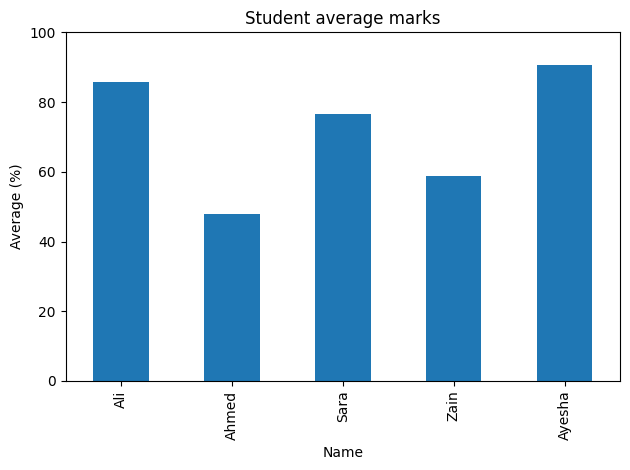

In [8]:
import matplotlib.pyplot as plt

df.plot(x="Name", y="Average (%)", kind="bar", legend=False, title="Student average marks")
plt.ylabel("Average (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Evidence E: Visualize subject averages

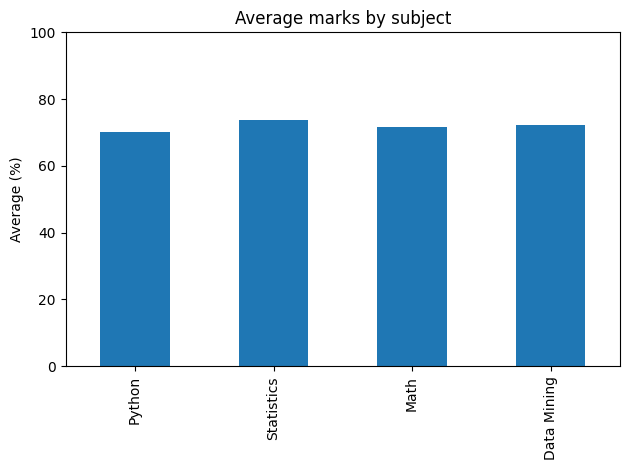

In [9]:
subject_averages.plot(kind="bar", title="Average marks by subject")
plt.ylabel("Average (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


## Conclusion
The sample analysis demonstrates how marks and attendance can be organized, summarized, and flagged using transparent rules. These results can help educators **review** records and decide where supportive follow-up may be useful.

## Missing evidence and limitations
- **Real dataset:** The current records are invented for demonstration; no real class dataset was supplied.
- **Validated thresholds:** Rules are illustrative and have not been validated against academic outcomes.
- **Research question and success criteria:** A formal project should define what it aims to assess (for example, students who may benefit from tutoring).
- **Privacy and fairness:** Use authorized, anonymized data; review flags with educators and students rather than treating them as labels.
- Do not claim this notebook predicts dropout or proves causation.